<hr size=5 color='#002883'>

<p align="center"> <font size=7 color='#002883'> Elaboração de cartas sinóticas para identificação do South America Low Level Jet (SALLJ)

<hr size=5 color='#002883'>

<p align="left"> <font size=5 color='#002883'> Professora:  

* Prof. Dra. Rita Yuri Ynoue

<p align="left"> <font size=5 color='#002883'> Monitor PAE:

* Ronald Guiuseppi Ramírez Nina [PhD. Candidate in Atmospheric Sciences]
* email: ronald.ramirez.nina@alumni.usp.br / ronald.ramirez.nina@usp.br

<hr size=5 color='#002883'>

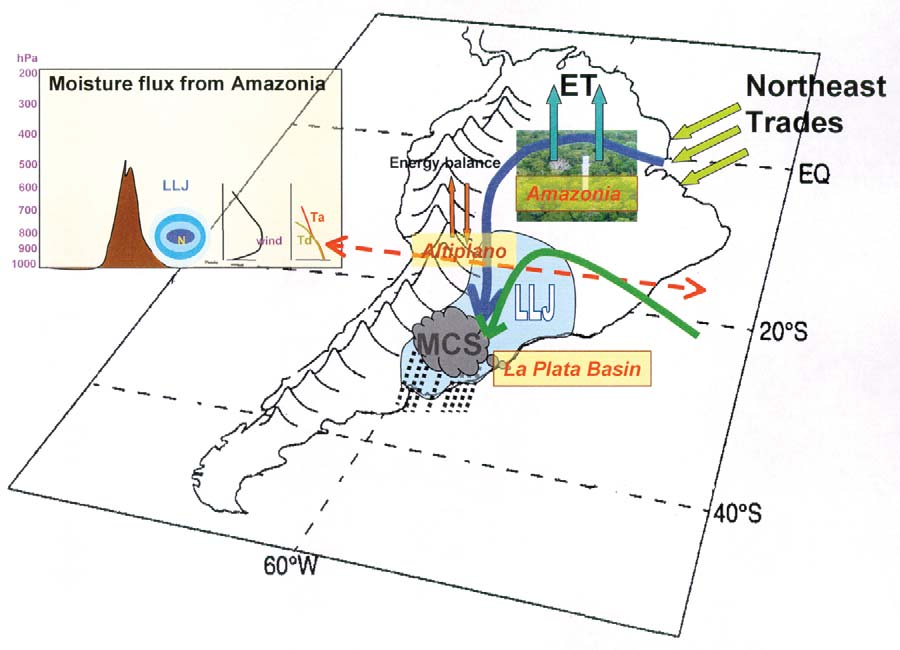


**Source:**

*   **Vera, C., Baez, M., Douglas, M., Emmanuel, C. B., Marengo, J., Meitin, J. Nicolini, M., Nogues-Paegle, J., Paegle, J., Penalba, O., Salio, P., Saulo, C., Silva Dias, M. A. and Zipser, E., 2006. The South American Low-Level Jet Experiment (SALLJEX). Bulletin of the American Meteorological Society, 87, 63-77.**

<hr size=5 color='#002883'>

# <font size=6 color='#002883'> **1. preparação do Colab** <font>

<font size=4 color='#002883'> Executar as três células de abaixo: <font>

<font size=4 color='#002883'>1.1. Montar o drive para acesso a nossa pasta de trabalho <font>

In [ ]:
# @title #### <font color='#002883'> Montar o drive para a importação da livraria utilities_new_version <font>
%%capture

from google.colab import drive
drive.mount('/content/drive')

<font size=4 color='#002883'>1.2. Adicionar o caminho do sistema para a importação do utilities_new_version.py <font>

In [ ]:
# @title #### <font color='#002883'> Adicionar o caminho do Drive ao caminho do sistema para importação de módulos <font>
%%capture

import sys
sys.path.append('/content/drive/MyDrive/')

<font size=4 color='#002883'>1.3. Instaçaão de livrarias <font>

In [44]:
# @title #### <font color='#002883'> Instalar livrarias <font>
%%capture

!pip install imgaug
!pip install siphon

# Instalando a Biblioteca Pygrib
!pip install pygrib
#print('\n')

# Instalando a Biblioteca Cartopy
!pip install cartopy
!pip install shapely --no-binary shapely --force
#print('\n')

# Instalando a Biblioteca MetPy
!pip install "numpy<2.0" metpy --upgrade
#!pip install MetPy
#print('\n')

# Instalando a Biblioteca Boto3
!pip install boto3
#print('\n')

# Instalando a Biblioteca NetCDF4
!pip install netcdf4
#print('\n')

# Instalando regionmask
!pip install regionmask

# Instalando a biblioteca para trabalhar arquivos .grib com a livraria xarray
!pip install -q cfgrib eccodes

# Instalando / atualizando a Biblioteca GDAL
!apt-add-repository -y ppa:ubuntugis/ubuntugis-unstable
!add-apt-repository -y ppa:ubuntugis/ppa
!apt-get install gdal-bin
!pip install 'gdal==3.0.4'
#print('\n')

# Install ImageMagick
!sudo apt install imagemagick
#print('\n')

# ============================================================
# BACKEND INTERATIVO PARA GOOGLE COLAB
# ============================================================
!pip install -q --upgrade ipympl ipywidgets

<font size=4 color='#002883'>1.4. Reiniciar a sessão de trabalho. Necessário para a importação do módulo de Metpy <font>

In [ ]:
# @title #### <font color='#002883'> Reiniciar sessão devido ao modulo do Metpy <font>
%%capture

import os
os.kill(os.getpid(), 9)

<font size=4 color='#002883'> **2. Fazer downloand de arquivos complementários (e.g., shapefile de estados e provincias do Brasil e outros paises). Além disso, fazer o download do arquivo utilities.py para o uso no processamento de imagens de satélite da série GOES. Download do arquivo CPT para o realce do canal infravermelho e vapor d'água.** <font>

In [1]:
# @title #### <font color='#002883'> Baixar arquivos complementários <font>
%%capture

# Baixando o shapefile dos estados brasileiros
!wget -c https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados brasileiros
!unzip -o br_unidades_da_federacao.zip
#print('\n')

# Baixando o shapefile dos estados / províncias mundiais
!wget -c https://www.naturalearthdata.com/http//www.naturalearthdata.com/download/10m/cultural/ne_10m_admin_1_states_provinces.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados / províncias mundiais
!unzip -o ne_10m_admin_1_states_provinces.zip
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais IR)
!wget -c https://www.dropbox.com/s/fdgnaqt91cy3x97/IR4AVHRR6.cpt
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais WV)
!wget -c https://www.dropbox.com/s/4l9fys6pv5c68xk/SVGAWVX_TEMP.cpt
#print('\n')

<font size=4 color='#002883'> **3. Importar livrarias.** <font>

In [1]:
# @title #### <font color='#002883'> Importar livrarias para o processamento dos dados <font>
%%capture

from datetime import datetime
import os
import requests
import time as t
import sys

# Livrarias para leitura, processamento e plot de dados NetCDF
from netCDF4 import Dataset
from osgeo import gdal
import matplotlib.pyplot as plt
import cartopy, cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import os
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm, ListedColormap
from datetime import timedelta, date, datetime
import pygrib
import xarray as xr
gdal.PushErrorHandler('CPLQuietErrorHandler')

# Livrarias para o cálculo de campos meteorológicos
from metpy.units import units
import metpy.calc as mpcalc
import numpy.ma as ma

<font size=4 color='red'> **4.1. Função para o download dos dados do modelo Global forecasting System (GFS).** <font>

In [2]:
# @title #### <font color='red'> Construir função para o download dos arquivos do GFS <font>
%%capture

# Link (select "grib filter" and check "Show the URL only for web programming" to verify the URL's):
# https://nomads.ncep.noaa.gov/

def download_gfs(date, iii):

    # Create the URL's based on the resolution
    if (resolution == '25'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '50'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2full.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '1'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_'+resolution+'p00.pl?file=gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)
        res = 'prgb2.'+resolution+'p00.f'

    # Print the file name
    print("File name: ", file_name)
    # Sends a GET request to the specified url
    myfile = requests.get(url)

    # Download the file
    open(dir + '//' + file_name, 'wb').write(myfile.content)

<font size=4 color='red'> **4.2. Função para o download de dados do Geostationary Operational Environmental Satellite - 19 (GOES-19) do Amazon Web Services (AWS).** <font>

In [3]:
# @title #### <font color='red'> Construir função para o download dos arquivos do GOES-19 <font>
%%capture

# ==========================================================================================================
# Training: Python and GOES-19 Imagery: Functions for download data from AWS
# ==========================================================================================================
# Required modules
import os                                # Miscellaneous operating system interfaces
import numpy as np                       # Import the Numpy package
import colorsys                          # To make convertion of colormaps
import boto3                             # Amazon Web Services (AWS) SDK for Python
from botocore import UNSIGNED            # boto3 config
from botocore.config import Config       # boto3 config
import math                              # Mathematical functions
from datetime import datetime            # Basic Dates and time types
from osgeo import osr                    # Python bindings for GDAL
from osgeo import gdal                   # Python bindings for GDAL

#from netCDF4 import Dataset          # Read / Write NetCDF4 files
#import matplotlib.pyplot as plt      # Plotting library
#import cartopy, cartopy.crs as ccrs  # Plot maps
##import sys
#from datetime import timedelta, date, datetime   # Manipulate dates

# ==========================================================================================================
def loadCPT(path):

    try:
        f = open(path)
    except:
        print ("File ", path, "not found")
        return None

    lines = f.readlines()

    f.close()

    x = np.array([])
    r = np.array([])
    g = np.array([])
    b = np.array([])

    colorModel = 'RGB'

    for l in lines:
        ls = l.split()
        if l[0] == '#':
            if ls[-1] == 'HSV':
                colorModel = 'HSV'
                continue
            else:
                continue
        if ls[0] == 'B' or ls[0] == 'F' or ls[0] == 'N':
            pass
        else:
            x=np.append(x,float(ls[0]))
            r=np.append(r,float(ls[1]))
            g=np.append(g,float(ls[2]))
            b=np.append(b,float(ls[3]))
            xtemp = float(ls[4])
            rtemp = float(ls[5])
            gtemp = float(ls[6])
            btemp = float(ls[7])

        x=np.append(x,xtemp)
        r=np.append(r,rtemp)
        g=np.append(g,gtemp)
        b=np.append(b,btemp)

    if colorModel == 'HSV':
        for i in range(r.shape[0]):
            rr, gg, bb = colorsys.hsv_to_rgb(r[i]/360.,g[i],b[i])
        r[i] = rr ; g[i] = gg ; b[i] = bb

    if colorModel == 'RGB':
        r = r/255.0
        g = g/255.0
        b = b/255.0

    xNorm = (x - x[0])/(x[-1] - x[0])

    red   = []
    blue  = []
    green = []

    for i in range(len(x)):
        red.append([xNorm[i],r[i],r[i]])
        green.append([xNorm[i],g[i],g[i]])
        blue.append([xNorm[i],b[i],b[i]])

    colorDict = {'red': red, 'green': green, 'blue': blue}

    return colorDict

# ==========================================================================================================

def download_CMI(yyyymmddhhmn, band, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"
    product_name = "ABI-L2-CMIPF"

    # Initializes the S3 client
    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6C{int(band):02.0f}_G19_s{year}{day_of_year}{hour}{min}"

    # Search for the file on the server
    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Band-{band}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_PROD(yyyymmddhhmn, product_name, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6_G19_s{year}{day_of_year}{hour}{min}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_GLM(yyyymmddhhmnss, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%H")
    min = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%M")
    seg = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%S")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    product_name = "GLM-L2-LCFA"
    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}_G19_s{year}{day_of_year}{hour}{min}{seg}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmnss}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
# Function to convert lat / lon extent to GOES-19 extents
def convertExtent2GOESProjection(extent):
    GOES19_HEIGHT = 35786023.0
    # Longitude de sub-satélite do GOES-19 (GOES-East operacional)
    GOES19_LONGITUDE = -75.2

    a, b = latlon2xy(extent[1], extent[0])
    c, d = latlon2xy(extent[3], extent[2])
    return (a * GOES19_HEIGHT, c * GOES19_HEIGHT, b * GOES19_HEIGHT, d * GOES19_HEIGHT)

# ==========================================================================================================
# Functions to convert lat / lon extent to array indices
def geo2grid(lat, lon, nc):

    # Apply scale and offset
    xscale, xoffset = nc.variables['x'].scale_factor, nc.variables['x'].add_offset
    yscale, yoffset = nc.variables['y'].scale_factor, nc.variables['y'].add_offset

    x, y = latlon2xy(lat, lon)
    col = (x - xoffset)/xscale
    lin = (y - yoffset)/yscale
    return int(lin), int(col)

# ==========================================================================================================
def latlon2xy(lat, lon):
    # goes_imagery_projection:semi_major_axis
    req = 6378137 # meters
    #  goes_imagery_projection:inverse_flattening
    invf = 298.257222096
    # goes_imagery_projection:semi_minor_axis
    rpol = 6356752.31414 # meters
    e = 0.0818191910435
    # goes_imagery_projection:perspective_point_height + goes_imagery_projection:semi_major_axis
    H = 42164160 # meters
    # goes_imagery_projection: longitude_of_projection_origin
    lambda0 = -1.308996939

    # Convert to radians
    latRad = lat * (math.pi/180)
    lonRad = lon * (math.pi/180)

    # (1) geocentric latitude
    Phi_c = math.atan(((rpol * rpol)/(req * req)) * math.tan(latRad))
    # (2) geocentric distance to the point on the ellipsoid
    rc = rpol/(math.sqrt(1 - ((e * e) * (math.cos(Phi_c) * math.cos(Phi_c)))))
    # (3) sx
    sx = H - (rc * math.cos(Phi_c) * math.cos(lonRad - lambda0))
    # (4) sy
    sy = -rc * math.cos(Phi_c) * math.sin(lonRad - lambda0)
    # (5)
    sz = rc * math.sin(Phi_c)

    # x,y
    x = math.asin((-sy)/math.sqrt((sx*sx) + (sy*sy) + (sz*sz)))
    y = math.atan(sz/sx)

    return x, y

# ==========================================================================================================
# Function to reproject the data
def reproject(file_name, ncfile, array, extent, undef):

    # Read the original file projection and configure the output projection
    source_prj = osr.SpatialReference()
    source_prj.ImportFromProj4(ncfile.GetProjectionRef())

    target_prj = osr.SpatialReference()
    target_prj.ImportFromProj4("+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs")

    # Reproject the data
    GeoT = ncfile.GetGeoTransform()
    driver = gdal.GetDriverByName('MEM')
    raw = driver.Create('raw', array.shape[0], array.shape[1], 1, gdal.GDT_Float32)
    raw.SetGeoTransform(GeoT)
    raw.GetRasterBand(1).WriteArray(array)

    # Define the parameters of the output file
    kwargs = {'format': 'netCDF', \
            'srcSRS': source_prj, \
            'dstSRS': target_prj, \
            'outputBounds': (extent[0], extent[3], extent[2], extent[1]), \
            'outputBoundsSRS': target_prj, \
            'outputType': gdal.GDT_Float32, \
            'srcNodata': undef, \
            'dstNodata': 'nan', \
            'resampleAlg': gdal.GRA_NearestNeighbour}

    # Write the reprojected file on disk
    gdal.Warp(file_name, raw, **kwargs)


<font size=4 color='#002883'> **5. Download dos dados do modelo Global forecasting System (GFS). É necessário editar a data Year = YYYY, month = mm, day = dd e hour = hh. Os dados do GFS só estão disponíveis até 5 dias atrás da data atual.** <font>

In [4]:
# @title #### <font color='#002883'> Download dos dados do GFS <font>
#%%capture

# Configurar a data de acesso aos dados do GFS
year = 2026
month = 10
day = 24
hour = 00

# Extensão desejada - COLOCAR AQUI ENTRE ASPAS POIS É UMA STRING
# longitude de -180 a 180
min_lon = '-122.50'
max_lon = '12.50'
min_lat = '-80.0'
max_lat = '25.0'

print('---------------------------------------')
print('GFS Download (NOMADS) - Script started.')
print('---------------------------------------')

# Start the time counter
start_time = t.time()

# Data desejada (Únicamente os últimos 10 dias!): Formato - 'YYYY, MM, DD, HH'
dt = datetime(year, month, day, hour)
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite

#-----------------------------------------------------------------------------------------------------------

# Download diretório
dir = "Samples"; os.makedirs(dir, exist_ok=True)

# Data desajada (Únicamente os últimos 10 dias!): Formato - 'YYYYMMDD'
date = (f'{dt:%Y%m%d}')

# Resolução espacial desejada: '25' or '50' or '1'
resolution = '25' #'1'

# Hora de execução: '00' or '06' or '12' or '18'
#hour_run = '00'
hour_run=(f'{dt:%H}')

# Horas de previsão
hour_ini = 0  # Init time
hour_end = 0 # End time
hour_int = 3  # Interval

if (resolution == '25'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '50'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '1'):
  res = 'pgrb2.'+resolution+'p00.f'

#-----------------------------------------------------------------------------------------------------------

# Download loop
for hour in range(hour_ini, hour_end + 1, hour_int):
    print('\n---------------------')
    print('Downloading GFS File:')
    print('---------------------')
    print('Resolution: ' + resolution)
    print('Date: ' + date)
    print('Run: ' + hour_run)
    print('Forecast Hour: f' + str(hour).zfill(3))
    # Call the download function
    download_gfs(date,hour)

# End the time counter
print('\nTotal Processing Time:', round((t.time() - start_time),2), 'seconds.')

---------------------------------------
GFS Download (NOMADS) - Script started.
---------------------------------------

---------------------
---------------------
Resolution: 25
Date: 20261024
Run: 00
Forecast Hour: f000
File name:  gfs.t00z.pgrb2.0p25.f000

Total Processing Time: 19.46 seconds.


<font size=4 color='#002883'> **6. Download dos dados de satélite do GOES-19.** <font>

In [5]:
# @title #### <font color='#002883'> Download de GOES-19 <font>
#%%capture

# Seleção da extensão [min. lon, min. lat, max. lon, max. lat]
# Lembrar que longitude está definida entre -180 e 180
extent = [float(min_lon), float(min_lat), float(max_lon), float(max_lat)]

# Input e output directorios
input = "/content/Samples"; os.makedirs(input, exist_ok=True)
output = "/content/Output"; os.makedirs(output, exist_ok=True)

#-----------------------------------------------------------------------------------------------------------
date = (f'{dt:%Y%m%d}')
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite
hour_run=(f'{dt:%H}')

# Download the ABI file channel 13 - Clean IR
file_ir = download_CMI(yyyymmddhhmn, 13, input)

# Variable
var = 'CMI'
# Abrir o dado
img = gdal.Open(f'NETCDF:{input}/{file_ir}.nc:' + var)

# Ler os metadados
metadata = img.GetMetadata()
scale = float(metadata.get(var + '#scale_factor'))
offset = float(metadata.get(var + '#add_offset'))
undef = float(metadata.get(var + '#_FillValue'))
dtime = metadata.get('NC_GLOBAL#time_coverage_start')

# Carregar os dados
ds_cmi = img.ReadAsArray(0, 0, img.RasterXSize, img.RasterYSize).astype(float)

# Aplicar a escala, offset e converter de Kelvin para Graus Celcius
ds_cmi = (ds_cmi * scale + offset) - 273.15

# Reprojeção do arquivo
filename_ret = f'{output}/IR_{yyyymmddhhmn}.nc'
reproject(filename_ret, img, ds_cmi, extent, undef)

# Ler a imagem do GOES-19 reprojetada
file = Dataset(filename_ret)

# Acessar aos valores dos pixel
data = file.variables['Band1'][:]

File /content/Samples/OR_ABI-L2-CMIPF-M6C13_G19_s20262970000213_e20262970009534_c20262970009596.nc exists


/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


<font size=4 color='#002883'> **7. Definir os campos meteorológicos por níveis do GFS.** <font>

In [6]:
# @title #### <font color='#002883'> Definir as variáveis do GFS por níveis <font>
%%capture

# Ler o dado grib do GFS
grib = pygrib.open(f'Samples/gfs.t{hour_run}z.{res}000')

# Selecionar a variável
mslp = grib.select(name='Pressure reduced to MSL')[0]

# Acessar informação do arquivo
init  = str(mslp.analDate)      # Init date / time
run   = str(mslp.hour).zfill(2) # Run
ftime = str(mslp.forecastTime)  # Forecast hour
valid = str(mslp.validDate)     # Valid date / time
print('Init: ' + init + ' UTC')
print('Run: ' + run + 'Z')
print('Forecast: +' + ftime)
print('Valid: ' + valid + ' UTC')

# Ler a data da região específica
# Longitude tem que estar entre 0 e 360 graus
mslp, lats, lons = mslp.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])

# Converter para hPa
mslp = mslp / 100
# Selecionar a variável
prtwt = grib.select(name='Precipitable water')[0]
prtwt = prtwt.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_1000 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
hght_1000 = hght_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_850 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
hght_850 = hght_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_700 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Read the data for a specific region
hght_700 = hght_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_500 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
hght_500 = hght_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_250 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Read the data for a specific region
hght_250 = hght_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Calculate and smooth 1000-500 hPa thickness
thickness_1000_500 = hght_500 - hght_1000
# Calculate and smooth 1000-850 hPa thickness
thickness_1000_850 = hght_850 - hght_1000
# Calculate and smooth 1000-850 hPa thickness
thickness_850_500 = hght_500 - hght_850

# Selecionar a variável
u_925 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
u_925, lats, lons = u_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_925 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
v_925 = v_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
u_250 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
u_250, lats, lons = u_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_250 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
v_250 = v_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
w_850 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
w_850 = w_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
w_500 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Ler a data para a região específica
w_500 = w_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
temp_850 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
temp_850 = temp_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
relhum_800 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 800)[0]
# Ler a data para a região específica
relhum_800 = relhum_800.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_850 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
relhum_850 = relhum_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_700 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Ler a data para a região específica
relhum_700 = relhum_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Busca a variável de taxa de precipitação na superfície
precip_rate = grib.select(name='Precipitation rate', typeOfLevel='surface')[0]

# Busca a variável de pressão em superfície
surface_pressure = grib.select(name='Surface pressure', typeOfLevel='surface')[0]

#-----------------------------------------------------------------------------------------------------------

# calculando umidade relativa média entre 800 e 700 hPa
relhum = (relhum_800 + relhum_850 + relhum_700)/3

# Calculando divergencia em 925 hPa
nivel=925
pressure = units('Pa')*nivel*100
u_925 = units('m/s')*u_925
v_925 = units('m/s')*v_925
# Calculando com metpy
dx, dy = mpcalc.lat_lon_grid_deltas(lons, lats)
# Compute the divergence
div_925 = mpcalc.divergence(u_925, v_925, dx=dx, dy=dy)
# quero somente convergencia
mask_conv = ma.masked_greater_equal(div_925, 0).mask
div_925[mask_conv] = np.nan

# Calculando divergencia em 250 hPa
nivel=250
pressure = units('Pa')*nivel*100
u_250 = units('m/s')*u_250
v_250 = units('m/s')*v_250
# Calculando com metpy
dx, dy = mpcalc.lat_lon_grid_deltas(lons, lats)
# Compute the divergence
div_250 = mpcalc.divergence(u_250, v_250, dx=dx, dy=dy)
# quero somente divergencia
mask_div = ma.masked_less_equal(div_250, 0).mask
div_250[mask_div] = np.nan

# Quero somente os valores negativos de omega
mask_omega = ma.masked_greater_equal(w_850, 0).mask
w_850[mask_omega] = np.nan

mask_omega = ma.masked_greater_equal(w_500, 0).mask
w_500[mask_omega] = np.nan

# Quero somente valores maiores q 40
mask_prtwt = ma.masked_less(prtwt, 40).mask
prtwt[mask_prtwt] = np.nan

<font size=4 color='red'> **Observação: Para listar as variáveis disponíveis pelo modelo GFS, rodar a seguinte célular.** <font>

In [ ]:
# @title #### <font color='red'> Listar variáveis do modelo GFS <font>
%%capture

for grb in grib:
    print(grb)  # Imprime diretamente: número, nome, unidades, tipo de nível e valor do nível

grib.close()

<font size=4 color='#002883'> **8. Converter a Analysis do modelo GFS do formato .grib2 para o formato .nc (NetCDF). Com os dados no formato NetCDF é possível fazer os corter verticais para identificação do Jato Subtropical (JST) e do Jato Polar (JP)** <font>


<font size=4 color='red'> **Observação: Só as variáveis com níveis de pressão ("typeOfLevel": "isobaricInhPa") que serão transformadas do formato .grib2 para o formato .nc** <font>

In [12]:
# @title #### <font color='#002883'> Transformar do formato .grib2 para .nc (Só as variáveis com níveis de pressão que serão transformadas) <font>
#%%capture

import logging

# Silencia os logs do cfgrib
logging.getLogger("cfgrib").setLevel(logging.CRITICAL)

ds = xr.open_dataset(
    f'Samples/gfs.t{hour_run}z.{res}000',
    engine="cfgrib",
    backend_kwargs={
        "filter_by_keys": {
            "typeOfLevel": "isobaricInhPa"
        },
        "indexpath": ""
    }
)

ds

<xarray.Dataset> Size: 301MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
    valid_time     datetime64[ns] 8B ...
Data variables:
    gh             (isobaricInhPa, latitude, longitude) float32 30MB ...
    t              (isobaricInhPa, latitude, longitude) float32 30MB ...
    r              (isobaricInhPa, latitude, longitude) float32 30MB ...
    q              (isobaricInhPa, latitude, longitude) float32 30MB ...
    w              (isobaricInhPa, latitude, longitude) float32 30MB ...
    wz             (isobaricInhPa, latitude, longitude) float32 30MB ...
    u              (isobaricInhPa, latitude, longitude) float32 30MB ...
    v              (isobaricInhPa, latitude, longitude) float32 30MB ...
    absv           (isobaricInhPa, latitude, longitude) float32 30MB ...
    o3mr           (isobaricInhPa, latitude, longitude) float32 30MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T06:05 GRIB to CDM+CF via cfgrib-0.9.1...

In [21]:
# @title #### <font color='#002883'> Transformar do formato .grib2 para .nc (Só as variáveis com níveis de pressão que serão transformadas) <font>
#%%capture

import logging

# Silencia os logs do cfgrib
logging.getLogger("cfgrib").setLevel(logging.CRITICAL)

ds_sp = xr.open_dataset(
    f'Samples/gfs.t{hour_run}z.{res}000',
    engine="cfgrib",
    backend_kwargs={
        "filter_by_keys": {
            "typeOfLevel": "surface",
            "name": "Surface pressure"
        },
        "indexpath": ""
    }
)

# Converter para hPa
ds_sp["sp_hpa"] = ds_sp["sp"] / 100.0
ds_sp['sp_hpa'].attrs = {
    'long_name': 'Surface pressure in hPa',
    'units': 'hPa'
}

ds_sp

<xarray.Dataset> Size: 2MB
Dimensions:     (latitude: 421, longitude: 541)
Coordinates:
  * latitude    (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude   (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.0 12.25 12.5
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    valid_time  datetime64[ns] 8B ...
Data variables:
    sp          (latitude, longitude) float32 911kB 8.1e+04 ... 9.33e+04
    sp_hpa      (latitude, longitude) float32 911kB 810.0 809.1 ... 929.6 933.0
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T06:23 GRIB to CDM+CF via cfgrib-0.9.1...

In [22]:
# @title #### Preparar pressão de superfície para os cortes

# Fazer uma cópia apenas com a variável necessária
ds_sp_plot = ds_sp[['sp_hpa']].copy()

# Garantir nomes padrão de coordenadas, se necessário
rename_coords = {}
if 'lat' in ds_sp_plot.coords:
    rename_coords['lat'] = 'latitude'
if 'lon' in ds_sp_plot.coords:
    rename_coords['lon'] = 'longitude'

if rename_coords:
    ds_sp_plot = ds_sp_plot.rename(rename_coords)

# Ajustar longitude para -180 a 180, se necessário
if ds_sp_plot['longitude'].max() > 180:
    ds_sp_plot = ds_sp_plot.assign_coords(
        longitude=((ds_sp_plot['longitude'] + 180) % 360) - 180
    )
    ds_sp_plot = ds_sp_plot.sortby('longitude')

# Ordenar coordenadas para seleção/interpolação
ds_sp_plot = ds_sp_plot.sortby('latitude').sortby('longitude')

ds_sp_plot

<xarray.Dataset> Size: 919kB
Dimensions:     (latitude: 421, longitude: 541)
Coordinates:
  * latitude    (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude   (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.0 12.25 12.5
    time        datetime64[ns] 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    valid_time  datetime64[ns] 8B ...
Data variables:
    sp_hpa      (latitude, longitude) float32 911kB 810.0 809.1 ... 929.6 933.0
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T06:23 GRIB to CDM+CF via cfgrib-0.9.1...

<font size=4 color='#002883'> **9. Calculando a velocidade do vento considerando só as componentes zonal (u) e meridional (v). Além disso, calculando a Temperatura Potencial, Tempoteratura do ponto de orvalho, Temperatura Potencial Equivalente, convergência de umidade horizontal por níveis fazendo uso da livraria Metpy** <font>

In [23]:
# @title #### <font color='#002883'> Cálculo da magnitude da velocidade do vento e da Temperatura Potencial <font>
#%%capture

# =================================================================
# Cálculo da magnitude do vento e Jato de Altos Níveis
# =================================================================
# MAGNITUDE DO VENTO
ds['wind_speed'] = mpcalc.wind_speed(ds['u'], ds['v'])  #np.sqrt(ds['u']**2 + ds['v']**2)

# Use MetPy to calculate the wind speed for colorfill plot, change units to knots from m/s
speed_jet = mpcalc.wind_speed(u_250, v_250)

#Quero somente os valores maiores que 30 m/s
mask_jet = ma.masked_less_equal(speed_jet, 30).mask
speed_jet[mask_jet] = np.nan

# =================================================================
# Cálculo da Cizalhadura do vento entre 850 e 700 hPa
# =================================================================
# Ventos em 850 hPa
u850 = ds['u'].sel(isobaricInhPa=850)
v850 = ds['v'].sel(isobaricInhPa=850)

# Ventos em 700 hPa
u700 = ds['u'].sel(isobaricInhPa=700)
v700 = ds['v'].sel(isobaricInhPa=700)

# Componentes do cisalhamento vetorial
du = u700 - u850
dv = v700 - v850

# Magnitude do cisalhamento
ds['shear_850_700'] = np.hypot(du, dv)
ds['shear_850_700'].attrs = {
    'long_name': '850–700 hPa bulk wind shear',
    'units': 'm/s'
}

# =================================================================
# Cálculo da Temperatura Potencial, Temperatura do ponto de orvalho
# e Temperatura Potencial Equivalente
# =================================================================
# Temperatura Potencial
ds['theta'] = mpcalc.potential_temperature(ds['isobaricInhPa'], ds['t'])
ds['theta'].attrs['units'] = 'K'

# Temperatura do Ponto de Orvalho
ds['dewpoint'] = mpcalc.dewpoint_from_specific_humidity(ds['isobaricInhPa'], ds['q'])
ds['dewpoint'].attrs['units'] = 'K'

# Temperatura Potencial Equivalente
ds['theta_e'] = mpcalc.equivalent_potential_temperature(ds['isobaricInhPa'], ds['t'], ds['dewpoint'])
ds['theta_e'].attrs['units'] = 'K'

# =================================================================
# Cálculo da convergência de umidade por níveis
# =================================================================
# Extrair variáveis com unidades físicas
q = ds['q'].metpy.unit_array
u = ds['u'].metpy.unit_array
v = ds['v'].metpy.unit_array
# Fluxos horizontais de umidade
qu = q * u
qv = q * v

# Distâncias entre pontos da grade
dx, dy = mpcalc.lat_lon_grid_deltas(
    ds['longitude'].values,
    ds['latitude'].values
)
# Adicionar dimensão vertical para permitir broadcasting
dx = dx[np.newaxis, :, :]
dy = dy[np.newaxis, :, :]
# Convergência horizontal do fluxo de umidade
mfc = (-1) * mpcalc.divergence(
    qu,
    qv,
    dx=dx,
    dy=dy,
    x_dim=-1,
    y_dim=-2
)
# Armazenar no Dataset
ds['mfc'] = (ds['q'].dims, mfc.to('1/s').magnitude)
ds['mfc'].attrs = {
    'long_name': 'Moisture flux convergence',
    'units': 's-1'
}

# Calcular a Vorticidade Potencial Baroclínica
ds['pv'] = mpcalc.potential_vorticity_baroclinic(
    potential_temperature=ds['theta'],
    pressure=ds['isobaricInhPa'],
    u=ds['u'],
    v=ds['v']
)
ds['pv'].attrs['units'] = 'K * m^2 / (kg * s)'

# Converter o resultado para Unidades de Vorticidade Potencial (PVU)
# 1 PVU = 10^-6 K * m^2 / (kg * s)
ds['pv_pvu'] = ds['pv'] * 1e6
# Atualiza os atributos para exibição correta
#ds['pv_pvu'].attrs['units'] = 'PVU'
ds

<xarray.Dataset> Size: 692MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B 2026-10-24
    step           timedelta64[ns] 8B 00:00:00
    valid_time     datetime64[ns] 8B 2026-10-24
Data variables: (12/18)
    gh             (isobaricInhPa, latitude, longitude) float32 30MB -128.2 ....
    t              (isobaricInhPa, latitude, longitude) float32 30MB 259.6 .....
    r              (isobaricInhPa, latitude, longitude) float32 30MB 86.5 ......
    q              (isobaricInhPa, latitude, longitude) float32 30MB 0.001066...
    w              (isobaricInhPa, latitude, longitude) float32 30MB 0.12 ......
    wz             (isobaricInhPa, latitude, longitude) float32 30MB -0.01076...
    ...             ...
    theta          (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    dewpoint       (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    theta_e        (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    mfc            (isobaricInhPa, latitude, longitude) float64 60MB -3.972e-...
    pv             (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    pv_pvu         (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T06:05 GRIB to CDM+CF via cfgrib-0.9.1...

<font size=4 color='#002883'> **10. Velocidade do vento (Jet, m/s) + Altura Geopotencial (Z, dam) | Nível 250 hPa** <font>

In [24]:
# @title #### <font color='#002883'> Jato de Baixos Níveis da América do Sul (JBNAS) <font>

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from datetime import datetime

# =================================================================
# 1. Seleção das variáveis meteorológicas
# =================================================================

from metpy.units import units

# Função para extrair valores nas unidades desejadas
def valores(campo, unidade, unidade_original=None):
    """Converte campos Xarray, Pint ou NumPy para valores numéricos."""

    if hasattr(campo, 'metpy'):
        return campo.metpy.unit_array.to(unidade).magnitude

    if hasattr(campo, 'to'):
        return campo.to(unidade).magnitude

    if unidade_original is None:
        raise ValueError(
            "Campo NumPy sem unidades. Informe unidade_original."
        )

    return (np.asarray(campo) * units(unidade_original)).to(unidade).magnitude

# Campos meteorológicos em 850 hPa
speed850 = valores(
    ds['wind_speed'].sel(isobaricInhPa=850), 'm/s'
)

shear = valores(ds['shear_850_700'], 'm/s')

theta_e850 = valores(
    ds['theta_e'].sel(isobaricInhPa=850), 'K'
)

mfc850 = valores(
    ds['mfc'].sel(isobaricInhPa=850), '1/s'
)

u850 = valores(ds['u'].sel(isobaricInhPa=850), 'm/s')
v850 = valores(ds['v'].sel(isobaricInhPa=850), 'm/s')

# Espessura entre 850 e 500 hPa
thickness = (
    ds['thickness_850_500']
    if 'thickness_850_500' in ds
    else thickness_850_500
)

# Converter de metros para decâmetros
thickness_dam = valores(
    thickness,
    'dam',
    unidade_original='m'
)

# MFC em unidades de 10^-5 s^-1
mfc_plot = mfc850 * 1e5
mfc_masked = np.ma.masked_where(mfc_plot <= 0, mfc_plot)

# Máscaras meteorológicas
speed850_masked = np.ma.masked_where(
    speed850 < 12, speed850
)

shear_masked = np.ma.masked_where(
    (shear < 6) | (speed850 < 12), shear
)

mfc_masked = np.ma.masked_where(
    mfc_plot <= 0, mfc_plot
)

# Coordenadas
lon = ds['longitude'].values
lat = ds['latitude'].values


# =================================================================
# Máscara continental - Natural Earth
# =================================================================
import regionmask

# Contornos continentais em resolução de 1:10 milhões
land = regionmask.defined_regions.natural_earth_v5_0_0.land_10

# Máscara na grade original do GFS
land_mask = land.mask(
    ds['longitude'],
    ds['latitude']
).notnull().values

# Aplicar máscara continental aos campos meteorológicos
speed850_land = np.ma.masked_where(~land_mask, speed850_masked)
shear_land = np.ma.masked_where(
    (~land_mask) | (speed850_masked < 12) | (shear_masked < 6), shear_masked
)

thickness_land = np.ma.masked_where(~land_mask, thickness_dam)
theta_e_land = np.ma.masked_where(~land_mask, theta_e850)
mfc_land = np.ma.masked_where(~land_mask, mfc_masked)

# Vetores de vento somente sobre o continente
u850_land = np.ma.masked_where(~land_mask, u850)
v850_land = np.ma.masked_where(~land_mask, v850)


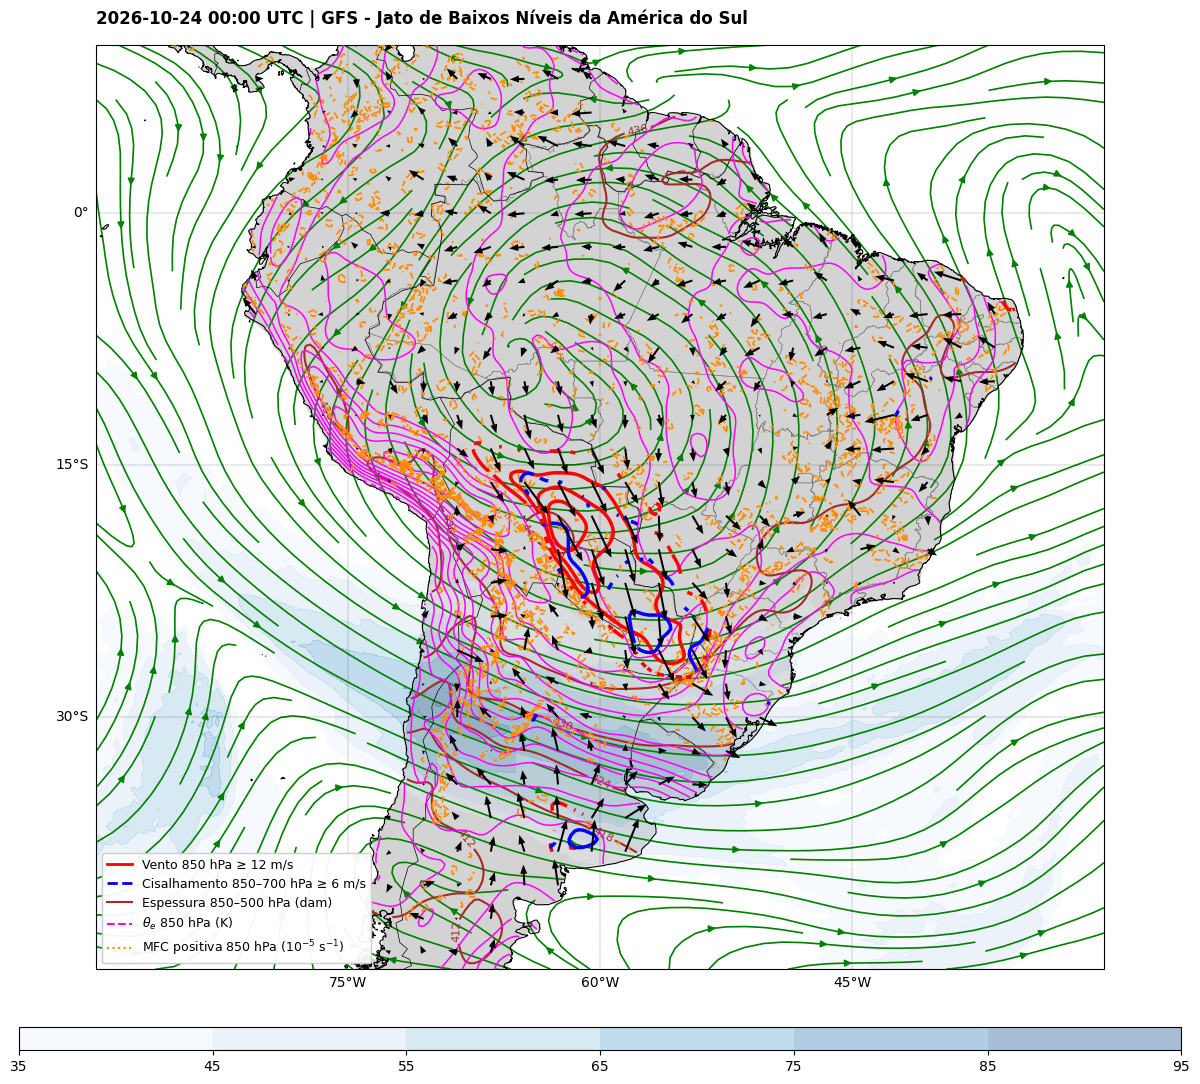

In [25]:
# =================================================================
# 2. Preparação da figura
# =================================================================
fig = plt.figure(figsize=(15, 15))
ax = plt.axes(projection=ccrs.PlateCarree())
# Seleção da extensão [min. lon, min. lat, max. lon, max. lat]
#ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())
ax.set_extent([-90, -30, -45, 10], crs=ccrs.PlateCarree())

transform = ccrs.PlateCarree()

# Fundo cartográfico
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=1)
ax.coastlines(resolution='10m', color='black', linewidth=0.8, zorder=3)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=0.5, zorder=3)

shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, transform, edgecolor='gray',
                  facecolor='none', linewidth=0.4, zorder=2)

# =================================================================
# 3. Espessura geopotencial entre 850 e 500 hPa - VERDE
# =================================================================
clev_thickness = np.arange(400, 620, 6)

# Suavizar variáveis
thickness_land_smooth = mpcalc.smooth_gaussian(thickness_land, 16)

cs_thick = ax.contour(
    lon, lat, thickness_land_smooth,
    levels=clev_thickness,
    colors='brown', linewidths=1.5,
    transform=transform, zorder=3
)
ax.clabel(cs_thick, fmt='%d', fontsize=8, inline=True)

# =================================================================
# 4. Temperatura potencial equivalente em 850 hPa - MAGENTA
# =================================================================
clev_theta = np.arange(280, 390, 4)

# Suavizar variáveis
theta_e_land_smooth = mpcalc.smooth_gaussian(theta_e_land, 16)

cs_theta = ax.contour(
    lon, lat, theta_e_land_smooth,
    levels=clev_theta,
    colors='magenta', linewidths=1.1,
    linestyles='-', transform=transform, zorder=4
)
#ax.clabel(cs_theta, fmt='%d', fontsize=8, inline=True)

# =================================================================
# 5. Convergência horizontal de umidade em 850 hPa - LARANJA
# =================================================================
# Apenas valores positivos (convergência)
clev_mfc = [0.5, 1, 2, 3, 5, 8, 12]

# Suavizar variáveis
mfc_land_smooth = mpcalc.smooth_gaussian(mfc_land, 16)

cs_mfc = ax.contour(
    lon, lat, mfc_land,
    #levels=clev_mfc,
    colors='darkorange', linewidths=1.3,
    linestyles='--', transform=transform, zorder=5
)

#ax.clabel(cs_mfc, fmt='%.1f', fontsize=8, inline=True)

# =================================================================
# 6. Isotacas do vento em 850 hPa >= 12 m/s - VERMELHO
# =================================================================
clev_wind = np.arange(12, 55, 3)

# Suavizar variáveis
speed850_land_smooth = mpcalc.smooth_gaussian(speed850_land, 12)

cs_wind = ax.contour(
    lon, lat, speed850_land_smooth,
    levels=clev_wind,
    colors='red', linewidths=2.5,
    transform=transform, zorder=7
)
#ax.clabel(cs_wind, fmt='%d', fontsize=9, inline=True)

# =================================================================
# 7. Cisalhamento entre 850 e 700 hPa >= 6 m/s - AZUL
# =================================================================
# Somente dentro das regiões com vento >= 12 m/s
clev_shear = np.arange(6, 36, 4)

# Suavizar variáveis
shear_land_smooth = mpcalc.smooth_gaussian(shear_land, 12)

cs_shear = ax.contour(
    lon, lat, shear_land_smooth,
    levels=clev_shear,
    colors='blue', linewidths=2.5,
    transform=transform, zorder=8
)
#ax.clabel(cs_shear, fmt='%d', fontsize=8, inline=True)

# =================================================================
# 8. Vetores do vento em 850 hPa
# =================================================================
skip = 8

Q = ax.quiver(
    lon[::skip], lat[::skip],
    u850_land[::skip, ::skip],
    v850_land[::skip, ::skip],
    color='black', scale=450, width=0.002,
    headwidth=3.5, headlength=4.5,
    transform=transform, zorder=9
)

ax.quiverkey(
    Q, X=0.88, Y=-0.08, U=12,
    label='12 m/s', labelpos='E',
    coordinates='axes'
)

# =================================================================
# 9. Identificação do Jato de Altos Níveis - Nível: 250 hPa
# =================================================================
clevjet = np.arange(35,96,10)
jet250 = ax.contourf(lons, lats, speed_jet, clevjet, cmap='Blues', alpha=0.35, zorder=2, transform=ccrs.PlateCarree())
plt.colorbar(jet250, orientation='horizontal', pad=0.05, aspect=50, extendrect=True)

# Suavizando os ventos
u_250_plot = mpcalc.smooth_gaussian(u_250, 16)
v_250_plot = mpcalc.smooth_gaussian(v_250, 16)
# Linhas de corrente
ax.streamplot(lons, lats, u_250_plot, v_250_plot, density=[1.75, 1.75], linewidth=1.2, color='green')

# =================================================================
# 10. Grade geográfica
# =================================================================
gl = ax.gridlines(
    crs=transform, color='black', alpha=0.7,
    linestyle='--', linewidth=0.25,
    xlocs=np.arange(-180, 180, 15),
    ylocs=np.arange(-90, 90, 15),
    draw_labels=True, zorder=9
)
gl.top_labels = False
gl.right_labels = False

# =================================================================
# 11. Título e legenda
# =================================================================
date = datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ')

ax.set_title(
    date.strftime('%Y-%m-%d %H:%M') +
    ' UTC | GFS - Jato de Baixos Níveis da América do Sul',
    fontweight='bold', fontsize=12, loc='left', pad=15
)

# Legenda das isolinhas
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color='red', lw=2,
           label='Vento 850 hPa ≥ 12 m/s'),
    Line2D([0], [0], color='blue', lw=2, ls='--',
           label='Cisalhamento 850–700 hPa ≥ 6 m/s'),
    Line2D([0], [0], color='brown', lw=1.5,
           label='Espessura 850–500 hPa (dam)'),
    Line2D([0], [0], color='magenta', lw=1.5, ls='--',
           label=r'$\theta_e$ 850 hPa (K)'),
    Line2D([0], [0], color='darkorange', lw=1.5, ls=':',
           label=r'MFC positiva 850 hPa ($10^{-5}$ s$^{-1}$)')
]

ax.legend(
    handles=legend_elements, loc='lower left',
    fontsize=9, framealpha=0.95
)

# =================================================================
# 12. Salvar figura
# =================================================================
plt.savefig(
    f'{output}/JBNAS_850hPa.png',
    bbox_inches='tight', pad_inches=0.1, dpi=300
)

plt.show()

In [29]:
# @title #### <font color='#002883'> Preparação das variáveis para os cortes verticais <font>

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

# Remover Pint somente para visualização
ds_plot = ds.metpy.dequantify().copy()

# Ordenar coordenadas
ds_plot = ds_plot.sortby('latitude').sortby('longitude')

# Fluxo meridional de umidade: qv
q = ds['q'].metpy.unit_array
v = ds['v'].metpy.unit_array
qv = (q * v).to('m/s')

# Converter para g kg-1 m s-1
ds_plot['qv_flux'] = (ds['q'].dims, qv.magnitude * 1000)

ds_plot['qv_flux'].attrs = {
    'long_name': 'Meridional moisture flux',
    'units': 'g kg-1 m s-1'
}

# ============================================================
# Adicionar pressão de superfície ao dataset dos cortes
# ============================================================

sp = ds_sp_plot['sp_hpa']

# Remover eventuais dimensões adicionais
for dim in sp.dims:
    if dim not in ['latitude', 'longitude']:
        sp = sp.isel({dim: 0}, drop=True)

# Garantir ordem das dimensões
sp = sp.transpose('latitude', 'longitude')

# Ajustar à grade do dataset principal
sp = sp.interp(
    latitude=ds_plot.latitude,
    longitude=ds_plot.longitude,
    method='linear'
)

# Armazenar
ds_plot['sp_hpa'] = sp

ds_plot['sp_hpa'].attrs = {
    'long_name': 'Surface pressure',
    'units': 'hPa'
}

ds_plot

<xarray.Dataset> Size: 724MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B 2026-10-24
    step           timedelta64[ns] 8B 00:00:00
    valid_time     datetime64[ns] 8B 2026-10-24
    surface        float64 8B ...
Data variables: (12/20)
    gh             (isobaricInhPa, latitude, longitude) float32 30MB -128.2 ....
    t              (isobaricInhPa, latitude, longitude) float32 30MB 259.6 .....
    r              (isobaricInhPa, latitude, longitude) float32 30MB 86.5 ......
    q              (isobaricInhPa, latitude, longitude) float32 30MB 0.001066...
    w              (isobaricInhPa, latitude, longitude) float32 30MB 0.12 ......
    wz             (isobaricInhPa, latitude, longitude) float32 30MB -0.01076...
    ...             ...
    theta_e        (isobaricInhPa, latitude, longitude) float64 60MB 262.6 .....
    mfc            (isobaricInhPa, latitude, longitude) float64 60MB -3.972e-...
    pv             (isobaricInhPa, latitude, longitude) float64 60MB -2.926e-...
    pv_pvu         (isobaricInhPa, latitude, longitude) float64 60MB -0.2926 ...
    qv_flux        (isobaricInhPa, latitude, longitude) float32 30MB -4.131 ....
    sp_hpa         (latitude, longitude) float64 2MB 810.0 809.1 ... 929.6 933.0
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T06:05 GRIB to CDM+CF via cfgrib-0.9.1...

In [30]:
# @title #### <font color='#002883'> Função para elaborar os cortes verticais do JBNAS <font>

def plot_vertical_jbnas(tipo, coordenada, limite_min, limite_max,
                        p_min=100, p_max=1000):

    # ============================================================
    # 1. Seleção do corte
    # ============================================================
    if tipo == 'longitude':
        fixo, horizontal = 'longitude', 'latitude'
        xlabel = 'Latitude'
    elif tipo == 'latitude':
        fixo, horizontal = 'latitude', 'longitude'
        xlabel = 'Longitude'
    else:
        raise ValueError("Utilize 'longitude' ou 'latitude'.")

    section = ds_plot.sel({fixo: coordenada}, method='nearest')

    section = section.where(
        (section[horizontal] >= limite_min) &
        (section[horizontal] <= limite_max),
        drop=True
    )

    section = section.where(
        (section.isobaricInhPa >= p_min) &
        (section.isobaricInhPa <= p_max),
        drop=True
    )

    # ============================================================
    # 2. Variáveis meteorológicas
    # ============================================================
    dims = ('isobaricInhPa', horizontal)

    speed = section['wind_speed'].transpose(*dims).values
    theta_e = section['theta_e'].transpose(*dims).values
    qv_flux = section['qv_flux'].transpose(*dims).values
    mfc = section['mfc'].transpose(*dims).values * 1e5
    # Pressão de superfície ao longo do corte
    sp_hpa = section['sp_hpa']
    # Remover dimensão vertical adicional, caso exista
    if 'isobaricInhPa' in sp_hpa.dims:
        sp_hpa = sp_hpa.isel(isobaricInhPa=0, drop=True)
    # Garantir uma dimensão horizontal
    sp_hpa = sp_hpa.transpose(horizontal).values

    x = section[horizontal].values
    pressure = section.isobaricInhPa.values
    coord_real = float(section[fixo].values)

    # ============================================================
    # Máscara abaixo do terreno
    # ============================================================
    below_ground = pressure[:, np.newaxis] > sp_hpa[np.newaxis, :]

    speed = np.ma.masked_where(below_ground, speed)
    theta_e = np.ma.masked_where(below_ground, theta_e)
    qv_flux = np.ma.masked_where(below_ground, qv_flux)
    mfc = np.ma.masked_where(below_ground, mfc)

    # ============================================================
    # 3. Figura e paleta
    # ============================================================
    fig, ax = plt.subplots(figsize=(15, 8))

    colors = [
        '#FFFFFF', '#FFE4C4', '#FFC38A',
        '#FF9363', '#F45148', '#CA202D', '#850016'
    ]

    levels_jet = [0, 12, 16, 20, 24, 30, 40, 60]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(levels_jet, cmap.N)

    # ============================================================
    # 4. Velocidade do vento - sombreado
    # ============================================================
    cf = ax.contourf(
        x, pressure, speed,
        levels=levels_jet,
        cmap=cmap, norm=norm,
        extend='max'
    )

    cs_speed = ax.contour(
        x, pressure, speed,
        levels=np.arange(12, 61, 4),
        colors='red', linewidths=1.1
    )
    ax.clabel(cs_speed, fmt='%d', fontsize=8)

    # ============================================================
    # 5. Temperatura potencial equivalente - magenta
    # ============================================================
    cs_theta = ax.contour(
        x, pressure, theta_e,
        levels=np.arange(290, 401, 10),
        colors='magenta', linewidths=1.1
    )
    ax.clabel(cs_theta, fmt='%d', fontsize=8)

    # ============================================================
    # 6. Fluxo meridional de umidade - verde
    # ============================================================
    cs_qv = ax.contour(
        x, pressure, qv_flux,
        levels=[20, 50, 100, 150, 200],
        colors='darkgreen',
        linewidths=1.4, linestyles='--'
    )
    ax.clabel(cs_qv, fmt='%d', fontsize=8)

    # ============================================================
    # 7. Convergência de umidade positiva - laranja
    # ============================================================
    cs_mfc = ax.contour(
        x, pressure, mfc,
        levels=[0.5, 1, 2, 3, 5, 8],
        colors='darkorange',
        linewidths=1.2, linestyles=':'
    )
    ax.clabel(cs_mfc, fmt='%.1f', fontsize=8)

    # ============================================================
    # Relevo dos Andes usando pressão de superfície
    # ============================================================
    surface_plot = np.clip(sp_hpa, p_min, p_max)

    ax.fill_between(x, surface_plot, p_max, color='dimgray', alpha=0.90, zorder=20)
    ax.plot(x, surface_plot, color='black', linewidth=1.5, zorder=21)

    # ============================================================
    # 8. Níveis isobáricos de referência
    # ============================================================
    for nivel in [850, 700]:
        ax.axhline(
            nivel, color='gray', linestyle='--',
            linewidth=0.7, alpha=0.7
        )

    # ============================================================
    # 9. Configuração dos eixos
    # ============================================================
    ax.set_yscale('log')
    ax.set_ylim(p_max, p_min)

    ticks = [1000, 925, 850, 700, 500, 400, 300, 250, 200, 150, 100]
    ticks = [p for p in ticks if p_min <= p <= p_max]

    ax.set_yticks(ticks)
    ax.set_yticklabels([str(p) for p in ticks])

    xticks = np.arange(
        np.ceil(limite_min / 10) * 10,
        limite_max + 1, 10
    )

    if horizontal == 'latitude':
        labels = [
            f'{abs(t):.0f}°S' if t < 0 else
            f'{t:.0f}°N' if t > 0 else '0°'
            for t in xticks
        ]
    else:
        labels = [
            f'{abs(t):.0f}°W' if t < 0 else
            f'{t:.0f}°E' if t > 0 else '0°'
            for t in xticks
        ]

    ax.set_xticks(xticks)
    ax.set_xticklabels(labels)

    ax.set_xlabel(xlabel, fontsize=12, fontweight='bold')
    ax.set_ylabel('Pressão (hPa)', fontsize=12, fontweight='bold')

    # ============================================================
    # 10. Título e legenda
    # ============================================================
    hemisferio = (
        ('W' if coord_real < 0 else 'E')
        if tipo == 'longitude'
        else ('S' if coord_real < 0 else 'N')
    )

    ax.set_title(
        f'JBNAS — Corte vertical em {abs(coord_real):.2f}°{hemisferio}\n'
        'Vento, temperatura potencial equivalente e transporte de umidade',
        fontsize=13, fontweight='bold', pad=14
    )

    cbar = fig.colorbar(
        cf, ax=ax, pad=0.02,
        aspect=30, ticks=levels_jet
    )
    cbar.set_label(
        'Velocidade do vento (m s$^{-1}$)', fontsize=11
    )

    legend_elements = [
        Line2D([0], [0], color='red', lw=1.5,
               label='Isotacas (m/s)'),
        Line2D([0], [0], color='magenta', lw=1.5,
               label=r'$\theta_e$ (K)'),
        Line2D([0], [0], color='darkgreen', lw=1.5,
               ls='--',
               label=r'$qv > 0$ (g kg$^{-1}$ m s$^{-1}$)'),
        Line2D([0], [0], color='darkorange', lw=1.5,
               ls=':',
               label=r'MFC positiva ($10^{-5}$ s$^{-1}$)')
    ]

    ax.legend(
        handles=legend_elements, loc='upper right',
        fontsize=9, framealpha=0.95
    )

    ax.grid(linestyle='--', alpha=0.2)
    plt.tight_layout()
    plt.show()

<font size=4 color='#002883'> **11. Corte vertical com Longitude constante para identificação do Jato Subtropical + Jato Polar Ramo Norte + Jato Polar Ramo Sul** <font>

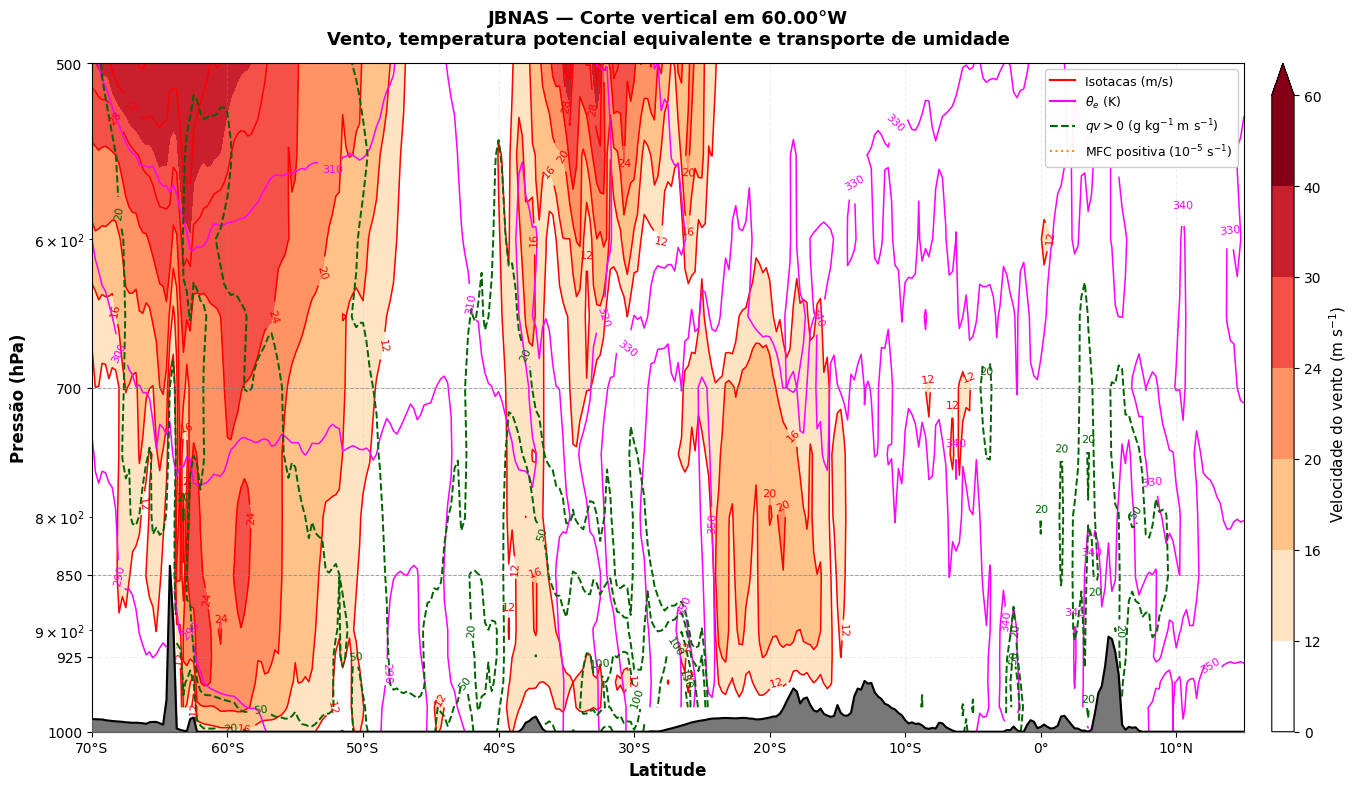

In [31]:
# @title #### <font color='#002883'> Corte vertical - Longitude constante: JBNAS <font>

# Configurações do corte
lon_corte = -60.0

lat_min = -70
lat_max = 15

p_min = 500
p_max = 1000

# Elaborar figura
plot_vertical_jbnas(
    tipo='longitude',
    coordenada=lon_corte,
    limite_min=lat_min,
    limite_max=lat_max,
    p_min=p_min,
    p_max=p_max
)

<font size=4 color='#002883'> **12. Corte vertical com Latitude constante para identificação do Jato Subtropical + Jato Polar Ramo Norte + Jato Polar Ramo Sul** <font>

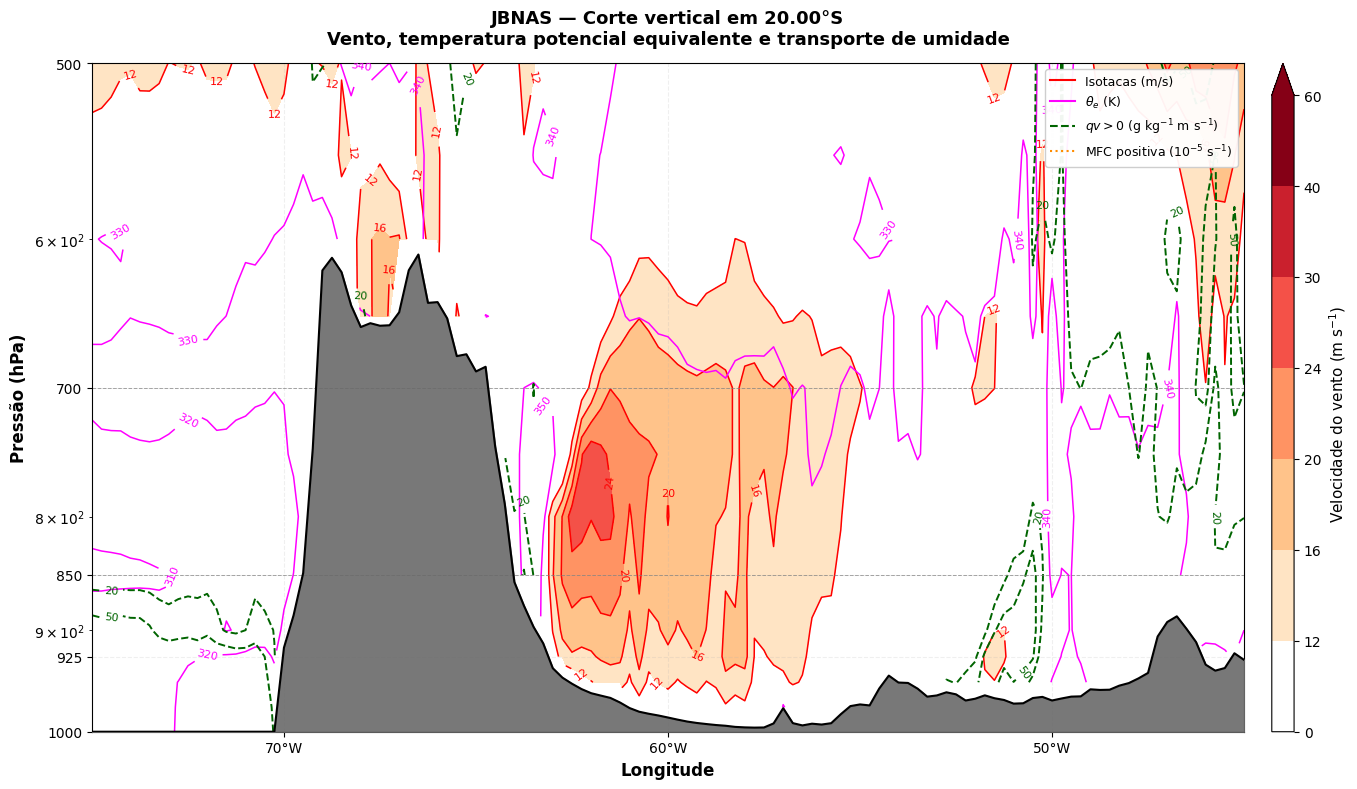

In [32]:
# @title #### <font color='#002883'> Corte vertical - Latitude constante: JBNAS <font>

# Configurações do corte
lat_corte = -20.0

lon_min = -75
lon_max = -45

p_min = 500
p_max = 1000

# Elaborar figura
plot_vertical_jbnas(
    tipo='latitude',
    coordenada=lat_corte,
    limite_min=lon_min,
    limite_max=lon_max,
    p_min=p_min,
    p_max=p_max
)

<font size=8 color='RED'> **13. Corte vertical interativo A–B para identificação do Jato Subtropical + Jato Polar Ramo Norte + Jato Polar Ramo Sul** <font>

<font size=4 color='#002883'> **Instalação e configuração do backend interativo para Google-Colab** <font>

In [33]:
# @title #### <font color='#002883'> Backend interativo para Google-Colab <font>
#%%capture

# ============================================================
# BACKEND INTERATIVO PARA GOOGLE COLAB
# ============================================================
from google.colab import output
output.enable_custom_widget_manager()

import ipympl

%matplotlib widget

import matplotlib.pyplot as plt

<font size=4 color='#002883'> **Importar livrarias necessárias para o plot interativo** <font>

In [34]:
# @title #### <font color='#002883'> Corte vertical interativo A-B: Jato Subtropical e Jato Polar <font>

# ============================================================
# IMPORTS
# ============================================================

import os
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

import metpy.calc as mpcalc

from pyproj import Geod

import ipywidgets as widgets
from IPython.display import display, clear_output
print("Backend:", plt.get_backend())

Backend: module://ipympl.backend_nbagg


<font size=8 color='RED'> **CORTE VERTICAL INTERATIVO:**  

1.   **EXECUTAR A CÉLULAR**
2.   **QUANDO O MAPA COM O CAMPO DE MAGNITUDE DO VENTO APARECER, SELECIONAR OS DOIS PONTO "A" E "B"**
3.   **DEPOIS DE SELECIONAR OS PONTOS, DAR CLIC NO BOTOM GERAR CORTE A-B** <font>

Procedimento: execute as células de preparação e a função do corte. Na última célula, o mapa e os controles aparecem juntos: selecione A, selecione B e clique em Gerar corte A–B. O perfil vertical será mostrado abaixo do mapa; Limpar pontos permite repetir a análise.

In [38]:
# @title #### 13.2 - Preparação dos dados do JBNAS

# ============================================================
# 1. Remover Pint somente para visualização
# ============================================================

ds_xs = ds.metpy.dequantify().copy()
ds_xs = ds_xs.sortby('latitude').sortby('longitude')

# ============================================================
# Preparar pressão de superfície para o corte interativo
# ============================================================

sp = ds_sp_plot['sp_hpa']

# Remover somente dimensões extras de tamanho 1
sp = sp.squeeze(drop=True)

# A pressão de superfície deve ser bidimensional
sp = sp.transpose('latitude', 'longitude')

# Alinhar à grade horizontal do GFS
sp = sp.interp(
    latitude=ds_xs.latitude,
    longitude=ds_xs.longitude,
    method='linear'
)

# Remover uma versão anterior, se existir
if 'sp_hpa' in ds_xs:
    ds_xs = ds_xs.drop_vars('sp_hpa')

# Incorporar pressão de superfície
ds_xs['sp_hpa'] = sp

ds_xs['sp_hpa'].attrs = {
    'long_name': 'Surface pressure',
    'units': 'hPa'
}

# ============================================================
# 2. Fluxo meridional de umidade
# ============================================================

# q em kg/kg e v em m/s
# Resultado em g kg-1 m s-1
ds_xs['qv_flux'] = ds_xs['q'] * ds_xs['v'] * 1000.0
ds_xs['qv_flux'].attrs['units'] = 'g kg-1 m s-1'

# ============================================================
# 3. Configurações do mapa e corte
# ============================================================

MAP_EXTENT = [-90, -30, -45, 10]

P_TOP = 500.0
P_BOTTOM = 1000.0

SPACING_KM = 25.0

# Configurações para visualização
WIND_THRESHOLD = 12.0
SHEAR_THRESHOLD = 6.0

# Sobreposição opcional do jato em 250 hPa no mapa
SHOW_JET250 = True

# Geodésia WGS84
geod = Geod(ellps='WGS84')

# Coordenadas
lon = ds_xs['longitude'].values
lat = ds_xs['latitude'].values

# ============================================================
# 4. Campos horizontais em 850 hPa
# ============================================================

speed850 = ds_xs['wind_speed'].sel(isobaricInhPa=850).values
u850 = ds_xs['u'].sel(isobaricInhPa=850).values
v850 = ds_xs['v'].sel(isobaricInhPa=850).values

shear850_700 = ds_xs['shear_850_700'].values
theta_e850 = ds_xs['theta_e'].sel(isobaricInhPa=850).values
mfc850 = ds_xs['mfc'].sel(isobaricInhPa=850).values * 1e5

# ============================================================
# 5. Espessura 850-500 hPa em dam
# ============================================================

# Utilizar diretamente as alturas geopotenciais em metros
thickness_dam = (
    ds_xs['gh'].sel(isobaricInhPa=500).values -
    ds_xs['gh'].sel(isobaricInhPa=850).values
) / 10.0

# ============================================================
# 6. Máscara continental
# ============================================================

# Utilizar a máscara land_mask calculada anteriormente
# (matriz booleana da grade do GFS).

land_mask = np.asarray(land_mask, dtype=bool)

speed_land = np.ma.masked_where(~land_mask, speed850)
shear_land = np.ma.masked_where(
    (~land_mask) | (speed850 < WIND_THRESHOLD),
    shear850_700
)

theta_land = np.ma.masked_where(~land_mask, theta_e850)
mfc_land = np.ma.masked_where(~land_mask, mfc850)
thickness_land = np.ma.masked_where(~land_mask, thickness_dam)

u_land = np.ma.masked_where(~land_mask, u850)
v_land = np.ma.masked_where(~land_mask, v850)

print('Dataset preparado para o corte interativo A-B.')

Dataset preparado para o corte interativo A-B.


In [39]:
# @title #### 13.3 - Funções do corte vertical A-B do JBNAS

# ============================================================
# 1. Funções auxiliares
# ============================================================

def fmt_lat(y):
    return f'{abs(y):.1f}°S' if y < 0 else f'{y:.1f}°N'

def fmt_lon(x):
    return f'{abs(x):.1f}°W' if x < 0 else f'{x:.1f}°E'


# ============================================================
# 2. Construir trajetória geodésica
# ============================================================

def build_geodesic_path(point_A, point_B):

    lat_A, lon_A = point_A
    lat_B, lon_B = point_B

    az, _, distance_m = geod.inv(
        lon_A, lat_A, lon_B, lat_B
    )

    total_km = distance_m / 1000.0
    n = max(2, int(np.ceil(total_km / SPACING_KM)) + 1)

    intermediate = geod.npts(
        lon_A, lat_A, lon_B, lat_B, n - 2
    )

    lon_path = np.array(
        [lon_A] + [p[0] for p in intermediate] + [lon_B]
    )
    lat_path = np.array(
        [lat_A] + [p[1] for p in intermediate] + [lat_B]
    )

    _, _, distances = geod.inv(
        lon_path[:-1], lat_path[:-1],
        lon_path[1:], lat_path[1:]
    )

    distance_km = np.r_[
        0, np.cumsum(distances) / 1000.0
    ]

    return lat_path, lon_path, distance_km


# ============================================================
# 3. Interpolar campos ao longo da trajetória A-B
# ============================================================

def interpolate_section(lat_path, lon_path, distance_km):

    pressure = ds_xs['isobaricInhPa']

    source = ds_xs.where(
        (pressure >= P_TOP) & (pressure <= P_BOTTOM),
        drop=True
    )

    lat_da = xr.DataArray(
        lat_path, dims='distance',
        coords={'distance': distance_km}
    )
    lon_da = xr.DataArray(
        lon_path, dims='distance',
        coords={'distance': distance_km}
    )

    section = source.interp(
        latitude=lat_da,
        longitude=lon_da,
        method='linear'
    )

    return section


# ============================================================
# 4. Plotar o corte vertical
# ============================================================

def plot_vertical_jbnas_ab(point_A, point_B):

    lat_path, lon_path, distance_km = build_geodesic_path(
        point_A, point_B
    )

    section = interpolate_section(
        lat_path, lon_path, distance_km
    )

    # Campos com dimensões pressão x distância
    dims = ('isobaricInhPa', 'distance')

    speed = section['wind_speed'].transpose(*dims).values
    theta_e = section['theta_e'].transpose(*dims).values
    qv = section['qv_flux'].transpose(*dims).values
    mfc = section['mfc'].transpose(*dims).values * 1e5

    pressure = section['isobaricInhPa'].values

    # --------------------------------------------------------
    # Máscara abaixo da superfície, quando disponível
    # --------------------------------------------------------
    # ============================================================
    # Pressão de superfície ao longo do transecto A-B
    # ============================================================

    sp_hpa = section['sp_hpa']

    # Remover dimensão vertical indevida, caso exista
    if 'isobaricInhPa' in sp_hpa.dims:
        sp_hpa = sp_hpa.isel(isobaricInhPa=0, drop=True)

    # Garantir somente a dimensão de distância
    sp_hpa = sp_hpa.transpose('distance').values

    # Máscara dos níveis abaixo da superfície
    below_ground = pressure[:, None] > sp_hpa[None, :]

    # Aplicar máscara aos campos meteorológicos
    speed = np.ma.masked_where(below_ground, speed)
    theta_e = np.ma.masked_where(below_ground, theta_e)
    qv = np.ma.masked_where(below_ground, qv)
    mfc = np.ma.masked_where(below_ground, mfc)

    # --------------------------------------------------------
    # Figura
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(15, 8))

    # Velocidade do vento sombreada
    levels_speed = [0, 12, 16, 20, 24, 30, 40, 60]
    colors = [
        '#FFFFFF', '#FFE4C4', '#FFC38A',
        '#FF9363', '#F45148', '#CA202D', '#850016'
    ]

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(levels_speed, cmap.N)

    cf = ax.contourf(
        distance_km, pressure, speed,
        levels=levels_speed, cmap=cmap,
        norm=norm, extend='max'
    )

    # Isotacas de 12 m/s ou superiores
    cs_speed = ax.contour(
        distance_km, pressure, speed,
        levels=np.arange(12, 61, 4),
        colors='red', linewidths=1.0
    )
    ax.clabel(cs_speed, fontsize=8, fmt='%d')

    # Temperatura potencial equivalente
    cs_theta = ax.contour(
        distance_km, pressure, theta_e,
        levels=np.arange(290, 401, 10),
        colors='magenta', linewidths=1.1
    )
    ax.clabel(cs_theta, fontsize=8, fmt='%d')

    # Fluxo meridional de umidade - positivo e negativo
    qv_levels = [-200, -150, -100, -50, -20,
                  20,   50,  100, 150, 200]

    cs_qv = ax.contour(
        distance_km, pressure, qv,
        levels=qv_levels,
        colors='darkgreen',
        linestyles='--',
        linewidths=1.4
    )
    ax.clabel(cs_qv, fontsize=8, fmt='%d')

    # Convergência horizontal positiva de umidade
    cs_mfc = ax.contour(
        distance_km, pressure, mfc,
        levels=[0.5, 1, 2, 3, 5, 8],
        colors='darkorange',
        linestyles=':',
        linewidths=1.2
    )
    ax.clabel(cs_mfc, fontsize=8, fmt='%.1f')

    # --------------------------------------------------------
    # Relevo dos Andes usando pressão de superfície
    # --------------------------------------------------------
    surface_plot = np.clip(sp_hpa, P_TOP, P_BOTTOM)

    ax.fill_between(distance_km, surface_plot, P_BOTTOM, color='dimgray', alpha=0.90, zorder=20)
    ax.plot(distance_km, surface_plot, color='black', linewidth=1.5, zorder=21)

    # --------------------------------------------------------
    # Eixo vertical e referências
    # --------------------------------------------------------
    ax.set_yscale('log')
    ax.set_ylim(P_BOTTOM, P_TOP)

    ticks = [1000, 925, 850, 700, 500]

    ax.set_yticks(ticks)
    ax.set_yticklabels([str(p) for p in ticks])

    for level in [850, 700]:
        ax.axhline(
            level, color='gray',
            linestyle='--', alpha=0.5, linewidth=0.7
        )

    ax.set_xlim(0, distance_km[-1])
    ax.set_xlabel('Distância ao longo do corte A–B (km)',
                  fontsize=12, fontweight='bold')
    ax.set_ylabel('Pressão (hPa)',
                  fontsize=12, fontweight='bold')

    # --------------------------------------------------------
    # Título
    # --------------------------------------------------------
    title_A = f'{fmt_lat(point_A[0])}, {fmt_lon(point_A[1])}'
    title_B = f'{fmt_lat(point_B[0])}, {fmt_lon(point_B[1])}'

    ax.set_title(
        'JBNAS — Corte vertical interativo A–B\n'
        f'A: {title_A}  →  B: {title_B}\n'
        f'Distância total: {distance_km[-1]:.0f} km',
        fontsize=12, fontweight='bold', pad=12
    )

    cbar = fig.colorbar(cf, ax=ax, pad=0.02)
    cbar.set_label('Velocidade do vento (m s$^{-1}$)')

    legend = [
        Line2D([0], [0], color='red', lw=1.5,
               label='Isotacas (m/s)'),
        Line2D([0], [0], color='magenta', lw=1.5,
               label=r'$\theta_e$ (K)'),
        Line2D([0], [0], color='darkgreen', lw=1.5,
               ls='--', label=r'$qv$ (g kg$^{-1}$ m s$^{-1}$)'),
        Line2D([0], [0], color='darkorange', lw=1.5,
               ls=':', label=r'MFC ($10^{-5}$ s$^{-1}$)')
    ]

    ax.legend(handles=legend, loc='upper right', fontsize=9)
    ax.grid(linestyle='--', alpha=0.2)

    # --------------------------------------------------------
    # Pequeno mapa com a trajetória
    # --------------------------------------------------------
    # Minimapa no canto superior esquerdo
    # [esquerda, inferior, largura, altura]
    inset = fig.add_axes(
        #[0.12, 0.68, 0.20, 0.22],
        [0.08, 0.70, 0.18, 0.20],
        projection=ccrs.PlateCarree()
    )

    inset.set_extent(
        [min(lon_path) - 5, max(lon_path) + 5,
         min(lat_path) - 5, max(lat_path) + 5],
        crs=ccrs.PlateCarree()
    )

    inset.add_feature(cfeature.LAND, facecolor='lightgray')
    inset.coastlines(linewidth=0.5)
    inset.add_feature(cfeature.BORDERS, linewidth=0.4)

    inset.plot(
        lon_path, lat_path,
        color='red', linewidth=2,
        transform=ccrs.PlateCarree()
    )

    inset.scatter(
        [point_A[1], point_B[1]],
        [point_A[0], point_B[0]],
        color='black', s=30,
        transform=ccrs.PlateCarree()
    )

    inset.text(point_A[1], point_A[0], ' A',
               fontweight='bold', transform=ccrs.PlateCarree())
    inset.text(point_B[1], point_B[0], ' B',
               fontweight='bold', transform=ccrs.PlateCarree())

    plt.tight_layout()
    return fig

HTML(value='<b>Selecione o ponto A no mapa.</b>')

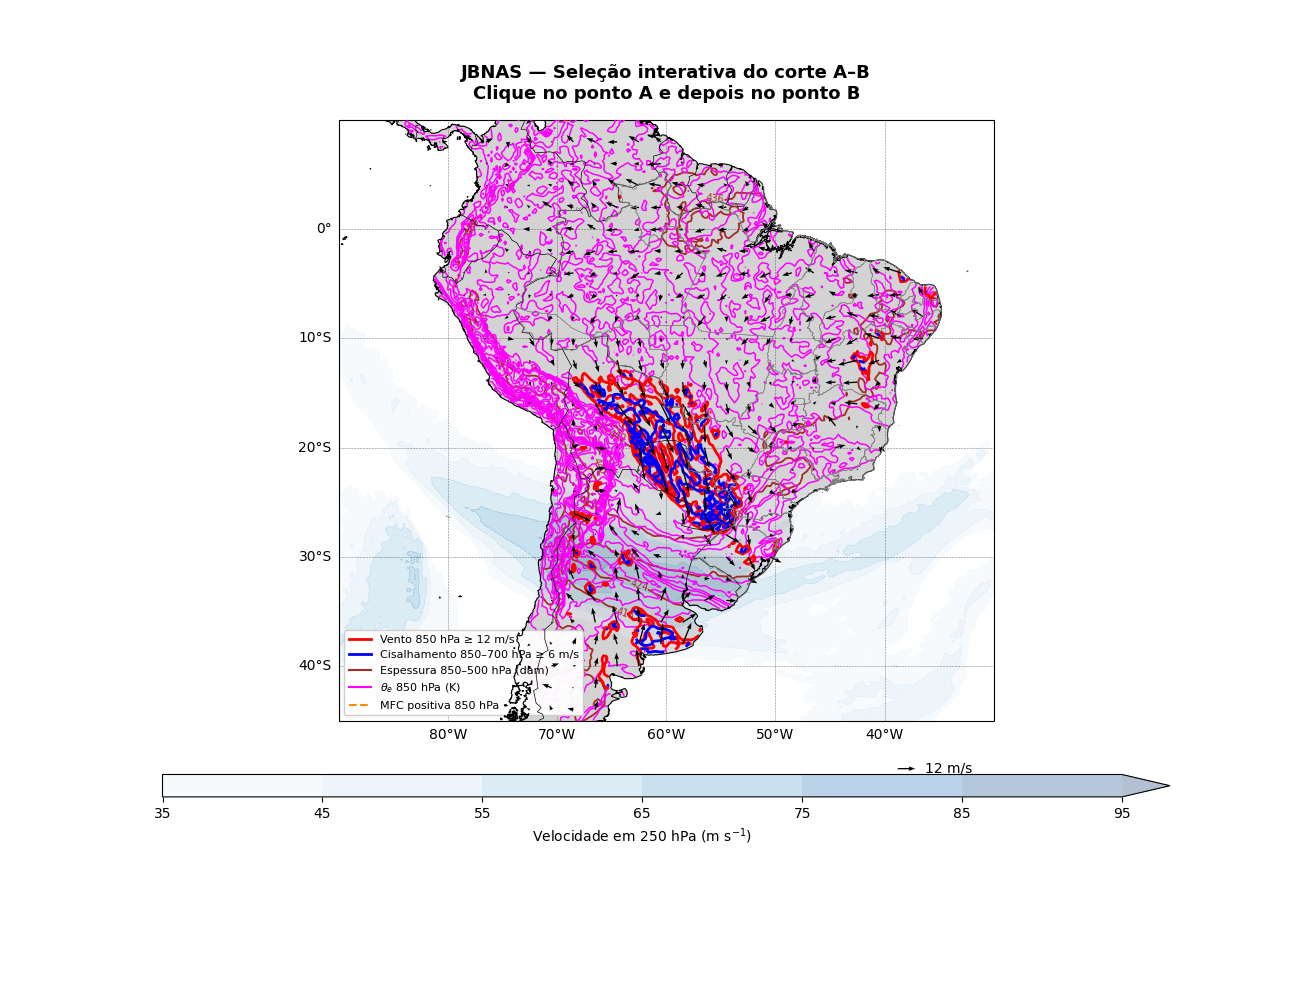

Output()

In [40]:
# @title #### 13.4 - Mapa interativo do JBNAS

# ============================================================
# 1. Preparar figura
# ============================================================

fig_map = plt.figure(figsize=(13, 10))
ax_map = plt.axes(projection=ccrs.PlateCarree())

ax_map.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())

transform = ccrs.PlateCarree()

ax_map.add_feature(
    cfeature.LAND, facecolor='lightgray', zorder=0
)
ax_map.coastlines(resolution='10m', linewidth=0.8, zorder=10)
ax_map.add_feature(
    cfeature.BORDERS, linewidth=0.5, zorder=10
)

if os.path.exists('BR_UF_2019.shp'):
    geometries = list(
        shpreader.Reader('BR_UF_2019.shp').geometries()
    )
    ax_map.add_geometries(
        geometries, transform,
        facecolor='none', edgecolor='gray',
        linewidth=0.4, zorder=10
    )

# ============================================================
# 2. Jato de 250 hPa - sombreado opcional
# ============================================================

if SHOW_JET250:
    speed250 = ds_xs['wind_speed'].sel(
        isobaricInhPa=250
    ).values

    jet250 = ax_map.contourf(
        lon, lat, speed250,
        levels=np.arange(35, 96, 10),
        cmap='Blues', alpha=0.30,
        extend='max', transform=transform,
        zorder=1
    )

    cb250 = fig_map.colorbar(
        jet250, ax=ax_map, orientation='horizontal',
        pad=0.07, aspect=45
    )
    cb250.set_label('Velocidade em 250 hPa (m s$^{-1}$)')

# ============================================================
# 3. Espessura geopotencial - marrom
# ============================================================

cs_thick = ax_map.contour(
    lon, lat, thickness_land,
    levels=np.arange(400, 620, 6),
    colors='brown', linewidths=1.3,
    transform=transform, zorder=3
)
ax_map.clabel(cs_thick, fmt='%d', fontsize=7)

# ============================================================
# 4. Temperatura potencial equivalente - magenta
# ============================================================

cs_theta = ax_map.contour(
    lon, lat, theta_land,
    levels=np.arange(280, 390, 4),
    colors='magenta', linewidths=1.1,
    transform=transform, zorder=4
)

# ============================================================
# 5. Convergência de umidade positiva - laranja
# ============================================================

cs_mfc = ax_map.contour(
    lon, lat, mfc_land,
    levels=[0.5, 1, 2, 3, 5, 8, 12],
    colors='darkorange',
    linestyles='--', linewidths=1.2,
    transform=transform, zorder=5
)

# ============================================================
# 6. Vento em 850 hPa - vermelho
# ============================================================

cs_wind = ax_map.contour(
    lon, lat, speed_land,
    levels=np.arange(12, 55, 3),
    colors='red', linewidths=2.0,
    transform=transform, zorder=7
)

# ============================================================
# 7. Cisalhamento 850-700 hPa - azul
# ============================================================

cs_shear = ax_map.contour(
    lon, lat, shear_land,
    levels=np.arange(6, 36, 4),
    colors='blue', linewidths=2.0,
    transform=transform, zorder=8
)

# ============================================================
# 8. Vetores do vento de 850 hPa
# ============================================================

skip = 8

Q = ax_map.quiver(
    lon[::skip], lat[::skip],
    u_land[::skip, ::skip],
    v_land[::skip, ::skip],
    color='black', scale=450,
    width=0.002, headwidth=3.5,
    transform=transform, zorder=9
)

ax_map.quiverkey(
    Q, 0.88, -0.08, 12,
    '12 m/s', labelpos='E',
    coordinates='axes'
)

# ============================================================
# 9. Grade
# ============================================================

gl = ax_map.gridlines(
    draw_labels=True,
    xlocs=np.arange(-180, 181, 10),
    ylocs=np.arange(-90, 91, 10),
    linewidth=0.4, color='black',
    alpha=0.5, linestyle='--'
)
gl.top_labels = False
gl.right_labels = False

# ============================================================
# 10. Título e legenda
# ============================================================

ax_map.set_title(
    'JBNAS — Seleção interativa do corte A–B\n'
    'Clique no ponto A e depois no ponto B',
    fontsize=13, fontweight='bold', pad=15
)

legend = [
    Line2D([0], [0], color='red', lw=2,
           label='Vento 850 hPa ≥ 12 m/s'),
    Line2D([0], [0], color='blue', lw=2,
           label='Cisalhamento 850–700 hPa ≥ 6 m/s'),
    Line2D([0], [0], color='brown', lw=1.5,
           label='Espessura 850–500 hPa (dam)'),
    Line2D([0], [0], color='magenta', lw=1.5,
           label=r'$\theta_e$ 850 hPa (K)'),
    Line2D([0], [0], color='darkorange', lw=1.5,
           ls='--', label='MFC positiva 850 hPa')
]

ax_map.legend(
    handles=legend, loc='lower left',
    fontsize=8, framealpha=0.95
)

# Manter a figura interativa disponível
# ============================================================
# 11. Controles interativos: mesma lógica do notebook original
# ============================================================
import io
import traceback
import ipywidgets as widgets
from IPython.display import display, clear_output, Image

selected_points = []
selection_artists = []
status = widgets.HTML(value='<b>Selecione o ponto A no mapa.</b>')
generate_button = widgets.Button(description='Gerar corte A-B', button_style='success', disabled=True)
reset_button = widgets.Button(description='Limpar pontos', button_style='warning')
output_cross_section = widgets.Output()

def onclick_jbnas(event):
    # Interagir apenas no mapa, com clique esquerdo e ferramentas pan/zoom desativadas
    if event.inaxes is not ax_map or event.xdata is None or event.ydata is None:
        return
    if event.button != 1 or len(selected_points) >= 2:
        return

    longitude, latitude = float(event.xdata), float(event.ydata)
    selected_points.append((latitude, longitude))
    label = 'A' if len(selected_points) == 1 else 'B'

    marker = ax_map.scatter(longitude, latitude, s=70, color='black',
                            edgecolor='white', linewidth=1, transform=transform, zorder=30)
    text_artist = ax_map.text(longitude, latitude, f' {label}', fontsize=13,
                              fontweight='bold', transform=transform, zorder=31)
    selection_artists.extend([marker, text_artist])

    if len(selected_points) == 1:
        status.value = f'<b>A = {fmt_lat(latitude)}, {fmt_lon(longitude)}.</b> Agora selecione B.'
    else:
        A, B = selected_points
        lat_path, lon_path, distance_km = build_geodesic_path(A, B)
        line, = ax_map.plot(lon_path, lat_path, color='lime', linewidth=2.5,
                            transform=transform, zorder=29)
        selection_artists.append(line)
        generate_button.disabled = False
        status.value = (f'<b>A = {fmt_lat(A[0])}, {fmt_lon(A[1])} | '
                        f'B = {fmt_lat(B[0])}, {fmt_lon(B[1])} | '
                        f'Distância = {distance_km[-1]:.0f} km.</b> '
                        'Clique em Gerar corte A-B.')
    fig_map.canvas.draw_idle()

def generate_jbnas_section(button):
    if len(selected_points) != 2:
        status.value = '<b>Selecione os pontos A e B.</b>'
        return

    with output_cross_section:
        clear_output(wait=True)
        try:
            # A função do corte retorna uma Figure Matplotlib.
            # Exibir PNG no Output evita um segundo canvas ipympl sem Comm ativo no Colab.
            fig_section = plot_vertical_jbnas_ab(*selected_points)
            if fig_section is None:
                raise RuntimeError('A função plot_vertical_jbnas_ab deve terminar com return fig.')
            buffer = io.BytesIO()
            fig_section.savefig(buffer, format='png', dpi=170, bbox_inches='tight')
            plt.close(fig_section)
            display(Image(data=buffer.getvalue()))
            status.value = '<b>Corte A-B gerado. Use Limpar pontos para selecionar outro.</b>'
        except Exception:
            status.value = '<b>Erro ao gerar o corte. Veja o traceback abaixo.</b>'
            traceback.print_exc()

def reset_jbnas(button):
    selected_points.clear()
    for artist in selection_artists:
        artist.remove()
    selection_artists.clear()
    generate_button.disabled = True
    status.value = '<b>Selecione o ponto A no mapa.</b>'
    with output_cross_section:
        clear_output()
    fig_map.canvas.draw_idle()

# ============================================================
# 12. Conectar callbacks e montar a interface, como na seção 13 original
# ============================================================
cid_jbnas = fig_map.canvas.mpl_connect('button_press_event', onclick_jbnas)
generate_button.on_click(generate_jbnas_section)
reset_button.on_click(reset_jbnas)

display(widgets.HBox([generate_button, reset_button]))
display(status)
plt.show()  # Exibe o mapa uma única vez, com canvas ipympl ativo
display(output_cross_section)  # O corte aparece abaixo após clicar no botão


Interface A–B integrada à célula anterior. Não execute a versão antiga dos controles; ela recriava botões e callbacks e podia desconectar o mapa da saída do corte.